In [4]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_completeness_v_measure,
)
from scipy.optimize import linear_sum_assignment

import warnings
warnings.filterwarnings("ignore")

In [5]:
# если данных нет, sklearn скачает их сам
data = fetch_20newsgroups(
    subset="all",
    remove=("headers", "footers", "quotes"),
)

texts = data.data
y = data.target


In [6]:
tfidf = TfidfVectorizer(
    max_features=20000,
    min_df=2,
    max_df=0.9,
    stop_words="english",
    sublinear_tf=True,
)

X = tfidf.fit_transform(texts)
print("TF-IDF:", X.shape)

TF-IDF: (18846, 20000)


In [7]:
# сжимаем и нормируем
svd = TruncatedSVD(n_components=150, random_state=0)
Z = svd.fit_transform(X)
Z = Normalizer().fit_transform(Z)

print("после svd:", Z.shape)
print("объяснённая дисперсия:", round(svd.explained_variance_ratio_.sum(), 4))

после svd: (18846, 150)
объяснённая дисперсия: 0.1304


In [5]:
# ищем k по silhouette
ks = list(range(10, 31))
sil = []

for k in ks:
    labels_k = KMeans(n_clusters=k, n_init=5, random_state=0).fit_predict(Z)
    score = silhouette_score(Z, labels_k, sample_size=3000, random_state=0)
    sil.append(score)
    print(k, round(score, 4))

best_k = ks[int(np.argmax(sil))]
print("best k по silhouette:", best_k)

10 0.0327
11 0.0342
12 0.0347
13 0.0389
14 0.0385
15 0.0394
16 0.0418
17 0.0431
18 0.041
19 0.0452
20 0.0478
21 0.0453
22 0.0438
23 0.0487
24 0.0486
25 0.0475
26 0.0472
27 0.0501
28 0.0481
29 0.0514
30 0.0526
best k по silhouette: 30


In [8]:
# финальная кластеризация
K = 20
km = KMeans(n_clusters=K, n_init=10, random_state=0)
labels = km.fit_predict(Z)

ari = adjusted_rand_score(y, labels)
nmi = normalized_mutual_info_score(y, labels)
h, c, v = homogeneity_completeness_v_measure(y, labels)

print("ARI:", round(ari, 4))
print("NMI:", round(nmi, 4))
print("homogeneity:", round(h, 4))
print("completeness:", round(c, 4))
print("v-measure:", round(v, 4))

ARI: 0.1843
NMI: 0.414
homogeneity: 0.3956
completeness: 0.4341
v-measure: 0.414


In [7]:
# purity через венгерский алгоритм
conf = np.zeros((K, len(data.target_names)), dtype=int)
for cl, true in zip(labels, y):
    conf[cl, true] += 1

row, col = linear_sum_assignment(-conf)
purity = conf[row, col].sum() / len(y)
print("purity:", round(purity, 4))

purity: 0.4024


In [8]:
# top-слова и главный класс каждого кластера
terms = np.array(tfidf.get_feature_names_out())

for cl in range(K):
    idx = np.where(labels == cl)[0]
    mean_tfidf = np.asarray(X[idx].mean(axis=0)).ravel()
    top = terms[np.argsort(mean_tfidf)[-8:]][::-1]

    counts = np.bincount(y[idx], minlength=len(data.target_names))
    top_class = data.target_names[int(np.argmax(counts))]

    print(f"{cl:2d} n={len(idx):4d} {top_class:32s} | {', '.join(top)}")

 0 n= 628 comp.os.ms-windows.misc          | windows, dos, file, ms, files, program, os, use
 1 n= 406 rec.motorcycles                  | bike, ride, dod, riding, bikes, just, road, motorcycle
 2 n=1317 rec.sport.hockey                 | game, team, games, year, hockey, season, players, play
 3 n= 970 talk.politics.guns               | gun, government, law, people, state, guns, rights, right
 4 n= 392 alt.atheism                      | post, know, like, thanks, mail, don, list, ll
 5 n=2307 sci.med                          | don, people, think, just, like, know, time, say
 6 n= 237 talk.politics.mideast            | armenian, armenians, turkish, turks, genocide, armenia, turkey, serdar
 7 n=1670 sci.electronics                  | use, like, just, power, used, mac, computer, apple
 8 n= 512 sci.crypt                        | key, clipper, encryption, chip, keys, government, escrow, nsa
 9 n= 500 comp.sys.ibm.pc.hardware         | card, video, bus, cards, drivers, monitor, isa, vga
10 n=

In [9]:
# 2D через t-SNE на выборке 5000
rng = np.random.RandomState(0)
idx = rng.choice(len(texts), 5000, replace=False)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=0,
    init="pca",
    learning_rate="auto",
)
Z2 = tsne.fit_transform(Z[idx])

print("t-SNE:", Z2.shape)

t-SNE: (5000, 2)


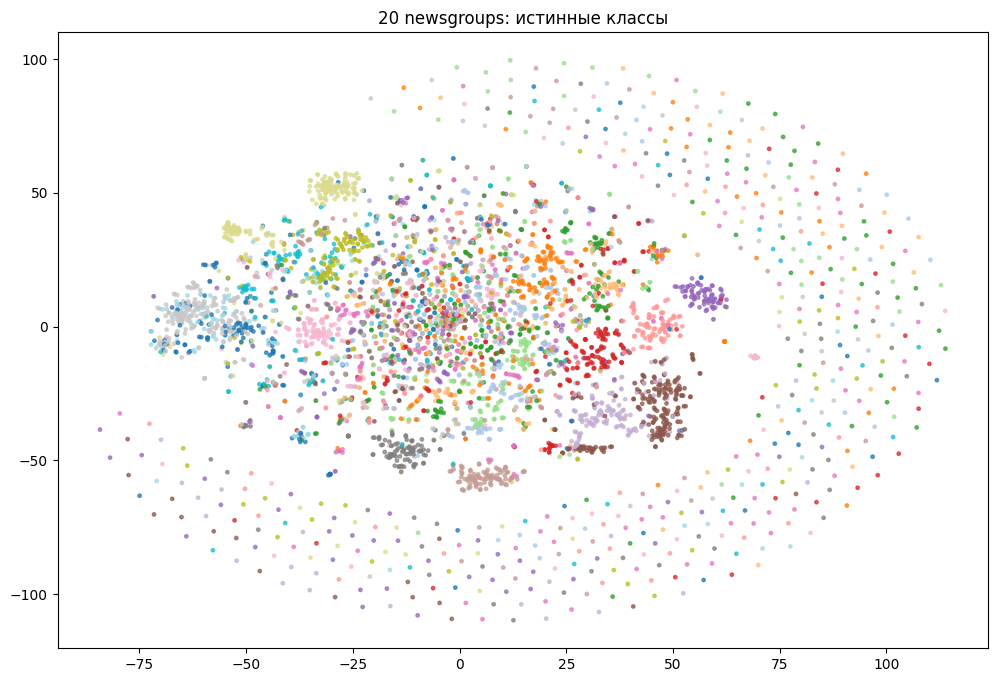

In [10]:
# истинные классы
plt.figure(figsize=(12, 8))
plt.scatter(Z2[:, 0], Z2[:, 1], c=y[idx], cmap="tab20", s=6, alpha=0.7)
plt.title("20 newsgroups: истинные классы")
plt.show()

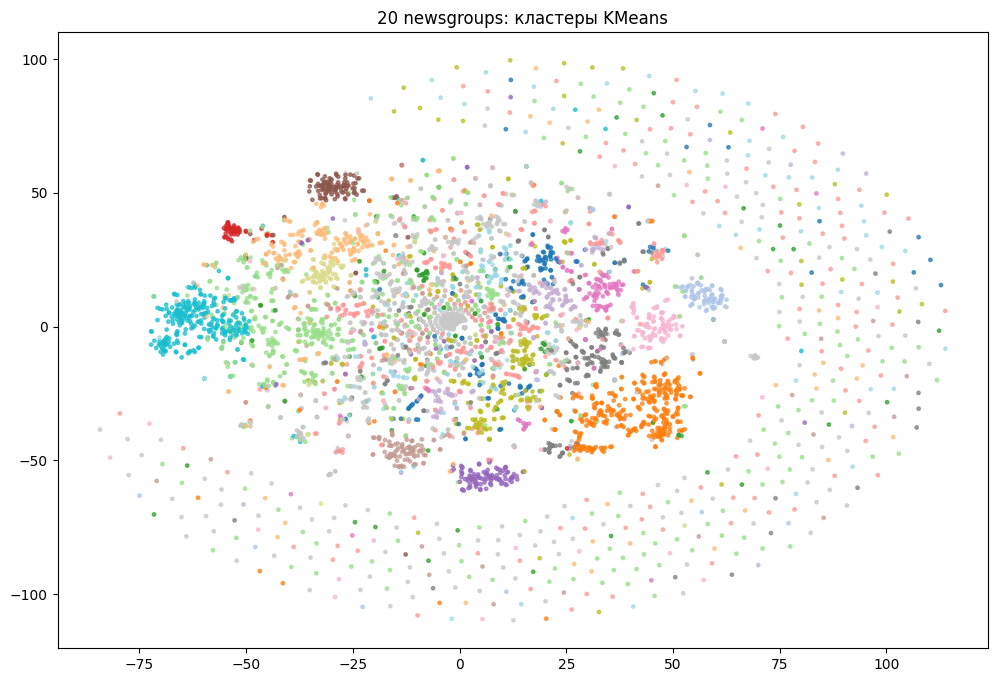

In [11]:
# найденные кластеры
plt.figure(figsize=(12, 8))
plt.scatter(Z2[:, 0], Z2[:, 1], c=labels[idx], cmap="tab20", s=6, alpha=0.7)
plt.title("20 newsgroups: кластеры KMeans")
plt.show()

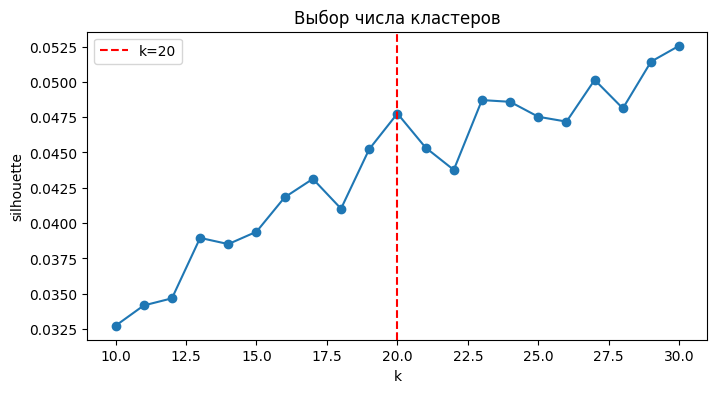

In [12]:
# кривая silhouette
plt.figure(figsize=(8, 4))
plt.plot(ks, sil, marker="o")
plt.axvline(20, color="red", linestyle="--", label="k=20")
plt.xlabel("k")
plt.ylabel("silhouette")
plt.title("Выбор числа кластеров")
plt.legend()
plt.show()